### Automatic Higher or Lower Game

In [1]:
from langgraph.graph import StateGraph, END
import random
from typing import Dict, List, TypedDict

In [2]:
class AgentState(TypedDict):
    name : str
    target_number : int
    guesses : List[int]
    attempts : int
    hint : str
    lower_b : int
    upper_b: int


In [3]:
def setup_node(state: AgentState)-> AgentState:
    """Initialize the game with a random target number"""

    state["name"] = f"Hi there{state["name"]}"
    state["target_number"] = random.randint(1,20)
    state["guesses"] = []
    state["attempts"] = 0
    state["hint"] = "Game started! Try to guess the number."
    state["lower_bound"] = 1 
    state["upper_bound"] = 20 
    print(f"{state['player_name']} The game has begun. I'm thinking of a number between 1 and 20.")
    
    return state




In [4]:
def guess_node(state : AgentState) -> AgentState:
    """Generate a smarter guess based on previous hints"""

    possible_guesses = [i for i in range(state["lower_b"], state["upperbound"]+1)if i not in state["guesses"]]

    if possible_guesses:
        guess = random.chance(possible_guesses)
    else:
        guess = random.randint(state["lower_b"], state["upper_b"])

    state["guesses"].append(guess)
    state["attempts"] += 1

    print(f"Attempt {state['attempts']}: Guessing {guess} (Current range: {state['lower_bound']}-{state['upper_bound']})")
    return state

In [5]:
def hint_node(state : AgentState)-> AgentState:
    """Indicates the Hint of the bounds"""
    latest_guess = state["guesses"][-1]
    target = state["target_number"]

    if latest_guess < target:
        state["hint"] = "Incorrect, Try Higher"
        state["lower_b"] = max(state["lower_b"], latest_guess + 1)
        print(f"Hint: {state['hint']}")

    elif latest_guess> target:
        state["hint"] = "Incorrect, Try Lower"
        state["upper_b"] = min(state["upper_b"],latest_guess - 1 )
        print(f"Hint: {state['hint']}")

    else:
        print(f"CORRECT, you found the {target} in {state["attempts"]}attempts")
    return state




In [6]:
def should_continue(state : AgentState) -> AgentState:
    """Decides whether to loop again"""
    latest_guess = state["guesses"][-1]
    target = state["target_number"]


    if latest_guess == target:
        print("GAME OVER")
        return "exit"
    
    elif state["attempts"] >= 7:
        print(f"GAME OVER: Maximum attempts reached! The number was {state['target_number']}")
        return "exit"   
    
    else:
        print(f"CONTINUING: {state['attempts']}/7 attempts used")
        return "loop"

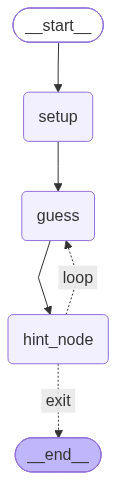

In [7]:
graph = StateGraph(AgentState)
graph.add_node("setup", setup_node)
graph.add_node("guess", guess_node)
graph.add_node("hint_node", hint_node)  

graph.set_entry_point("setup") 

graph.add_edge("setup", "guess")
graph.add_edge("guess", "hint_node")  

graph.add_conditional_edges(
    "hint_node",
    should_continue,

    {
        "loop": "guess",
        "exit": END
    }
)

app = graph.compile()
app

In [10]:
result = app.invoke({"name": "SAIF", "guesses": [], "attempts": 0, "lower_b": 1, "upper_b": 20})

KeyError: 'player_name'